# Machine Learning Lab: K-Means Clustering
## Breast Cancer Wisconsin (Diagnostic) Dataset

**Experiment:** Determine a suitable number of clusters using the Elbow Method (WCSS) and the Silhouette Score.

### Objectives
1. Load and inspect a built-in scikit-learn dataset.
2. Prepare numerical features for distance-based clustering.
3. Calculate Within-Cluster Sum of Squares (WCSS) for several values of *k*.
4. Evaluate candidate cluster counts using the Silhouette Score.
5. Fit a final K-Means model and examine the resulting groups.
6. Visualize clusters and compare them with the known diagnoses only after clustering.

### Dataset overview
The Breast Cancer Wisconsin (Diagnostic) dataset contains **569 observations**, **30 numerical features**, and two diagnosis labels: malignant and benign. K-Means will be trained using the 30 measurements only. The diagnosis labels are kept aside during model fitting and are used only for a supplementary comparison at the end.

The notebook uses a fixed random state so that the experiment can be reproduced.

### 1. Import the required libraries
The first cell imports the tools used throughout the experiment. `pandas` organizes the dataset, `matplotlib` creates the plots, and scikit-learn provides the dataset, scaler, clustering algorithm, dimensionality reduction, and evaluation measures.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 10})

### 2. Load the built-in dataset
`load_breast_cancer(as_frame=True)` returns the measurements in a DataFrame. The feature matrix `X` contains all 30 numerical measurements. The target series `y` stores the original diagnosis labels separately. The target is not included in the clustering input.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy()
y = cancer.target.copy()

print("Feature matrix shape:", X.shape)
print("Number of observations:", X.shape[0])
print("Number of numerical features:", X.shape[1])
print("Diagnosis labels:", list(cancer.target_names))
print("\nFirst five rows (six example features):")
print(X.iloc[:5, :6].to_string())

Feature matrix shape: (569, 30)
Number of observations: 569
Number of numerical features: 30
Diagnosis labels: [np.str_('malignant'), np.str_('benign')]

First five rows (six example features):
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness
0        17.99         10.38          122.80     1001.0          0.11840           0.27760
1        20.57         17.77          132.90     1326.0          0.08474           0.07864
2        19.69         21.25          130.00     1203.0          0.10960           0.15990
3        11.42         20.38           77.58      386.1          0.14250           0.28390
4        20.29         14.34          135.10     1297.0          0.10030           0.13280


<div class="page-break"></div>

### 3. Inspect the data
Before clustering, the dataset is checked for missing values, duplicate observations, data types, and the distribution of the known diagnosis labels. The diagnosis counts describe the original dataset; they are not used to create the clusters.

In [3]:
print("Missing values:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
print("\nData types:")
print(X.dtypes.value_counts().to_string())
print("\nSelected feature summary statistics:")
summary_columns = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean concavity"]
print(X[summary_columns].describe().round(2).to_string())
print("\nOriginal diagnosis distribution:")
print(y.map({0: "malignant", 1: "benign"}).value_counts().to_string())

Missing values: 0
Duplicate feature rows: 0

Data types:
float64    30

Selected feature summary statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean concavity
count       569.00        569.00          569.00     569.00           569.00          569.00
mean         14.13         19.29           91.97     654.89             0.10            0.09
std           3.52          4.30           24.30     351.91             0.01            0.08
min           6.98          9.71           43.79     143.50             0.05            0.00
25%          11.70         16.17           75.17     420.30             0.09            0.03
50%          13.37         18.84           86.24     551.10             0.10            0.06
75%          15.78         21.80          104.10     782.70             0.11            0.13
max          28.11         39.28          188.50    2501.00             0.16            0.43

Original diagnosis distribution:
target
benign       

### 4. Review the original class distribution
This bar chart describes the two known diagnosis categories. It provides context for the dataset, but the labels remain excluded from the K-Means fitting and from both cluster-count selection methods.

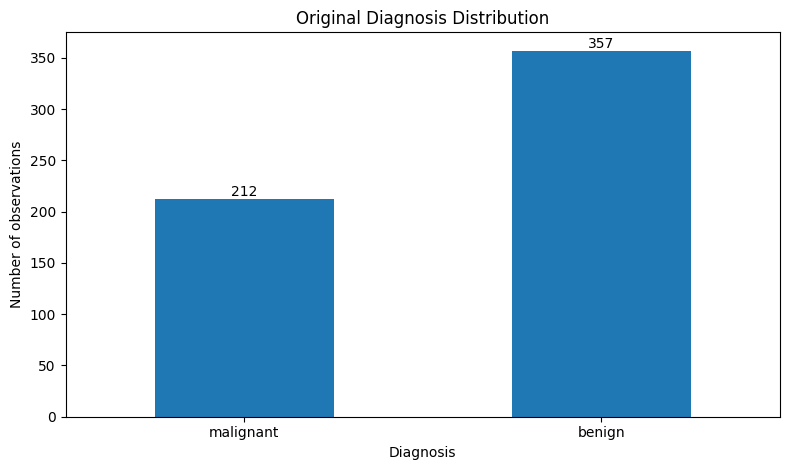

In [4]:
class_counts = y.map({0: "malignant", 1: "benign"}).value_counts().reindex(["malignant", "benign"])
ax = class_counts.plot(kind="bar", rot=0)
ax.set_title("Original Diagnosis Distribution")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of observations")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

<div class="page-break"></div>

### 5. Standardize the feature values
K-Means assigns observations using distances. The measurements in this dataset use different units and ranges, so features with large numerical magnitudes could dominate the distance calculation. `StandardScaler` transforms each feature to have an approximately zero mean and unit standard deviation. All 30 features are retained.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_summary = pd.DataFrame(X_scaled, columns=X.columns).agg(["mean", "std"]).T
print("Scaled feature check (first six features):")
print(scaled_summary.head(6).round(3).to_string())
print("\nScaled matrix shape:", X_scaled.shape)

Scaled feature check (first six features):
                  mean    std
mean radius       -0.0  1.001
mean texture       0.0  1.001
mean perimeter    -0.0  1.001
mean area         -0.0  1.001
mean smoothness   -0.0  1.001
mean compactness   0.0  1.001

Scaled matrix shape: (569, 30)


<div class="page-break"></div>

### 6. Calculate WCSS for the Elbow Method
WCSS is represented by the `inertia_` attribute of a fitted K-Means model. It is the sum of squared distances between each observation and its assigned cluster centroid. The loop fits models for *k* from 1 to 10 and records the WCSS value for each one. The diagnosis labels are not passed to K-Means.

In [6]:
k_values = list(range(1, 11))
wcss_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    model.fit(X_scaled)
    wcss_values.append(model.inertia_)

wcss_table = pd.DataFrame({"Number of clusters (k)": k_values, "WCSS": wcss_values})
print(wcss_table.to_string(index=False, formatters={"WCSS": "{:,.2f}".format}))

 Number of clusters (k)      WCSS
                      1 17,070.00
                      2 11,595.46
                      3 10,061.80
                      4  9,257.36
                      5  8,557.73
                      6  7,970.26
                      7  7,540.32
                      8  7,192.19
                      9  6,837.63
                     10  6,603.40


<div class="page-break"></div>

### 7. Plot the Elbow curve
The graph places the number of clusters on the horizontal axis and WCSS on the vertical axis. WCSS always decreases or stays the same as more clusters are added, so the aim is to find a point where the reduction begins to become less substantial. This point is a practical compromise between compact clusters and model complexity.

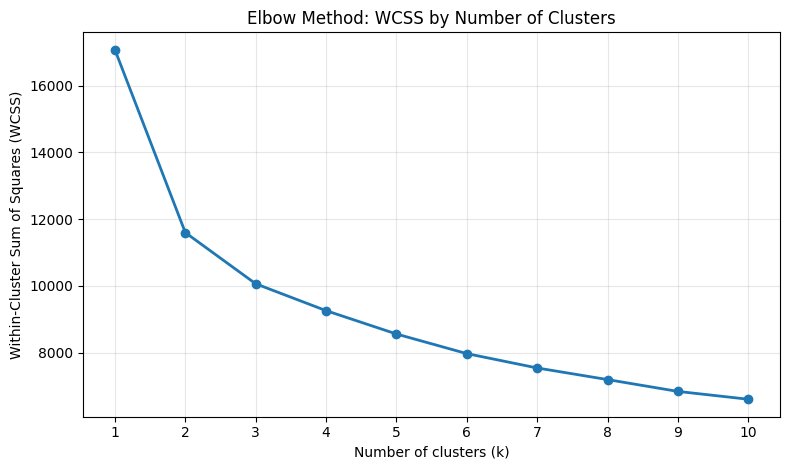

In [7]:
plt.figure(figsize=(8, 4.8))
plt.plot(k_values, wcss_values, marker="o", linewidth=2)
plt.xticks(k_values)
plt.title("Elbow Method: WCSS by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<div class="page-break"></div>

### 8. Calculate the Silhouette Score
The silhouette score compares the distance of an observation to its own cluster with its distance to the nearest alternative cluster. Scores range from -1 to 1. Higher positive values generally indicate more compact and better-separated clusters. The score is undefined for a one-cluster solution, so the evaluation begins at *k* = 2.

In [8]:
silhouette_values = []
silhouette_k_values = list(range(2, 11))

for k in silhouette_k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    cluster_labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of clusters (k)": silhouette_k_values,
    "Silhouette score": silhouette_values
})
best_k_silhouette = silhouette_k_values[int(np.argmax(silhouette_values))]
print(silhouette_table.to_string(index=False, formatters={"Silhouette score": "{:.4f}".format}))
print("\nHighest silhouette score occurs at k =", best_k_silhouette)

 Number of clusters (k) Silhouette score
                      2           0.3450
                      3           0.3144
                      4           0.2803
                      5           0.1585
                      6           0.1604
                      7           0.1532
                      8           0.1392
                      9           0.1470
                     10           0.1367

Highest silhouette score occurs at k = 2


<div class="page-break"></div>

### 9. Compare silhouette scores
This chart makes the separation quality of each candidate solution easier to compare. The largest score identifies the best result among the tested values of *k*. The score is considered together with the WCSS curve rather than treated as a universal guarantee of the true number of groups.

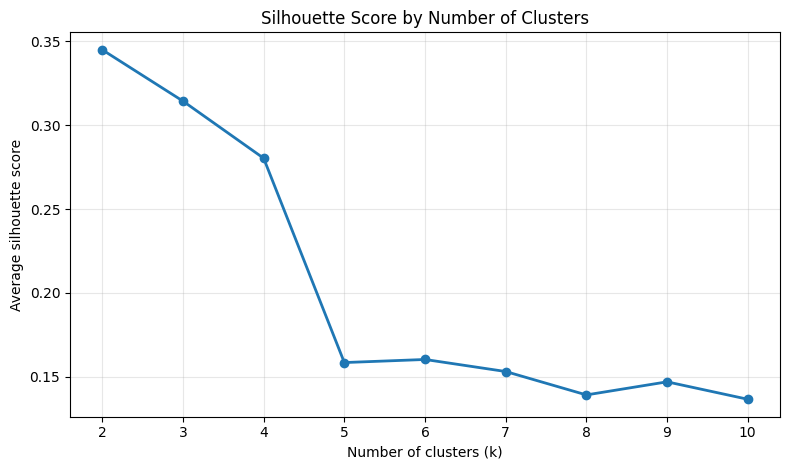

In [9]:
plt.figure(figsize=(8, 4.8))
plt.plot(silhouette_k_values, silhouette_values, marker="o", linewidth=2)
plt.xticks(silhouette_k_values)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<div class="page-break"></div>

### 10. Select the cluster count and fit the final model
For this run, the highest tested silhouette score is used as the primary selection criterion, while the WCSS curve is checked for a reasonable trade-off. The resulting value of *k* is then used to fit one final K-Means model. The model is trained only on the standardized measurements.

In [10]:
final_k = best_k_silhouette
kmeans = KMeans(n_clusters=final_k, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans.fit_predict(X_scaled)

cluster_sizes = pd.Series(cluster_labels, name="Cluster").value_counts().sort_index()
final_silhouette = silhouette_score(X_scaled, cluster_labels)
print("Selected number of clusters:", final_k)
print("Final WCSS:", round(kmeans.inertia_, 2))
print("Final silhouette score:", round(final_silhouette, 4))
print("\nCluster sizes:")
print(cluster_sizes.to_string())

Selected number of clusters: 2
Final WCSS: 11595.46
Final silhouette score: 0.345

Cluster sizes:
Cluster
0    189
1    380


### 11. Examine the cluster profiles
Cluster IDs are arbitrary identifiers, not diagnosis names. The table below reports average values for selected original measurements within each group. It can help describe how the clusters differ in their measured characteristics.

In [11]:
profile_columns = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean concavity", "mean concave points"]
cluster_profile = X.assign(cluster=cluster_labels).groupby("cluster")[profile_columns].mean().round(2)
print("Mean feature values by cluster (original measurement units):")
print(cluster_profile.to_string())

Mean feature values by cluster (original measurement units):
         mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean concavity  mean concave points
cluster                                                                                                            
0              17.56         21.36          116.41     993.67             0.10            0.18                 0.09
1              12.42         18.26           79.81     486.39             0.09            0.04                 0.03


<div class="page-break"></div>

### 12. Visualize the clusters with PCA
The clustering model uses all 30 standardized features. To display the result on a two-dimensional page, PCA projects the standardized observations into two principal components. This projection is for visualization only; it does not replace the 30-feature input used by K-Means. The projected centroids are also shown.

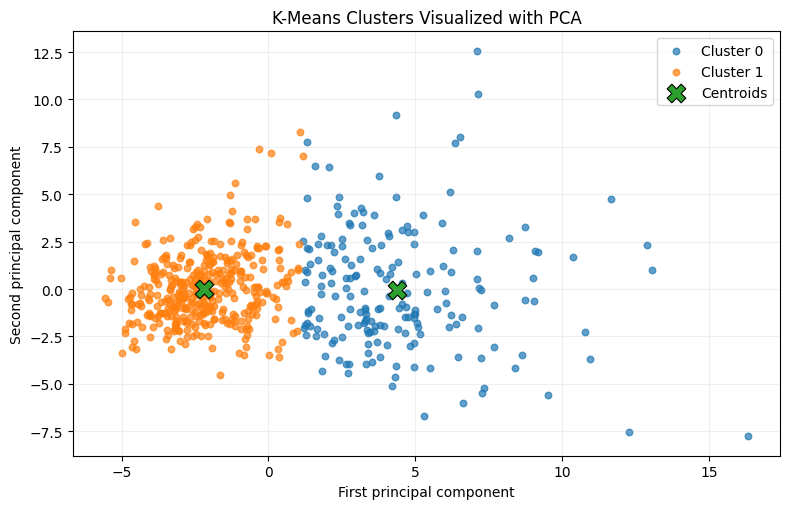

Variance explained by first two components: 0.6324


In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 5.2))
for cluster_id in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=22, alpha=0.7, label=f"Cluster {cluster_id}")
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], marker="X", s=180, edgecolor="black", linewidth=0.8, label="Centroids")
plt.title("K-Means Clusters Visualized with PCA")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("Variance explained by first two components:", round(pca.explained_variance_ratio_.sum(), 4))

<div class="page-break"></div>

### 13. Compare clusters with the known diagnoses
The original diagnosis column was not used during scaling, model fitting, or selection of *k*. It is now added only as an external reference to understand how the unsupervised groups align with the dataset's known categories. Cluster numbers may be swapped without changing the clustering, so the cross-tabulation is more informative than treating cluster IDs as predicted diagnosis labels.

In [13]:
diagnosis_names = y.map({0: "malignant", 1: "benign"})
comparison = pd.crosstab(diagnosis_names, pd.Series(cluster_labels, name="Cluster"))
ari = adjusted_rand_score(y, cluster_labels)

print("Diagnosis counts within each cluster:")
print(comparison.to_string())
print("\nAdjusted Rand Index (external comparison):", round(ari, 4))

Diagnosis counts within each cluster:
Cluster      0    1
target             
benign      14  343
malignant  175   37

Adjusted Rand Index (external comparison): 0.6707


<div class="page-break"></div>

### 14. Findings and interpretation

- The dataset contains 569 observations and 30 numerical measurements. No categorical encoding is required for the feature matrix.
- Standardization is important because K-Means is distance-based and the original measurements have different scales.
- WCSS decreases as *k* increases. The Elbow curve should be interpreted as a diminishing-returns guide, not as an exact mathematical rule.
- The silhouette score provides a separate measure of cluster cohesion and separation. In this run, the best score among the tested values occurs at **k = 2**.
- PCA provides a two-dimensional view of the clusters, while the final model itself uses all 30 standardized measurements.
- The known diagnoses are consulted only after fitting. Their agreement with the clusters is an external comparison, not evidence that K-Means was trained as a classifier.

### Learning outcomes
After completing this experiment, the learner should be able to prepare numerical data for K-Means, calculate and plot WCSS, evaluate candidate cluster counts with silhouette scores, fit a final clustering model, and interpret a cluster visualization.

### Conclusion
K-Means clustering was applied to the built-in Breast Cancer Wisconsin (Diagnostic) dataset. Candidate cluster counts were studied using both the Elbow Method and the Silhouette Score. The highest silhouette score in the tested range supported a two-cluster solution. The experiment demonstrates how internal clustering measures can guide model selection, while also showing why cluster labels must be interpreted independently of the original diagnosis labels.